# ETTm1 End-to-End Forecasting Notebook

This notebook implements a full ETTm1 forecasting workflow with standardized splits, metrics, and reporting conventions for reproducible comparison.
It covers data quality checks, feature preparation, baseline and conventional machine models, deep models, interpretability, ablations, robustness tests, and deployment-oriented conclusions.

## Table of Contents
1. Data Loading and Setup
2. Exploratory Data Analysis
3. Preprocessing and Feature Engineering
4. Baseline and Conventional Machine Models (with Optuna Tuning)
5. Deep Learning Models (with Optuna Tuning)
6. Model Comparison and Visualization
7. Interpretability and Error Diagnostics
8. Ablation Studies
9. Robustness and Stress Testing
10. Final Conclusions and Deployment Recommendations

# 1. Data Loading and Setup

This section configures reproducibility controls, runtime settings, and data paths, then loads the ETTm1 source data.
It establishes a deterministic and validated starting point for all downstream experiments.

In [1]:
# Data Loading and Setup
import os
import sys
import json
import time
import math
import hashlib
import random
import subprocess
import importlib
from pathlib import Path
from types import SimpleNamespace

# Data science and visualization stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML baseline models and preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor

# Deep Learning framework
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Time-series diagnostics and decomposition
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Optional dependencies for tuning and interpretability
try:
    import optuna
    OPTUNA_AVAILABLE = True
except Exception:
    OPTUNA_AVAILABLE = False

try:
    import shap
    SHAP_AVAILABLE = True
except Exception:
    SHAP_AVAILABLE = False

# Compute device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Global seed configuration for strict reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Environment logging for audit trails
print(f'Python: {sys.version.split()[0]}')
print(f'PyTorch: {torch.__version__}')
print(f'Pandas: {pd.__version__}')
print(f'NumPy: {np.__version__}')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'CUDA: {torch.version.cuda}')
    print(f'GPU: {torch.cuda.get_device_name(0)}')
print(f'Optuna available: {OPTUNA_AVAILABLE}')
print(f'SHAP available: {SHAP_AVAILABLE}')

Python: 3.13.12
PyTorch: 2.11.0+cu128
Pandas: 3.0.2
NumPy: 2.4.4
Device: cuda
CUDA: 12.8
GPU: NVIDIA GeForce GTX 1650 Ti
Optuna available: True
SHAP available: True


In [2]:
# Global experiment hyperparameters and model configurations
CONFIG = {
    'seed': SEED,
    'dataset_name': 'ETTm1',
    'paper_split': 'informer_ettm1_12_4_4',
    'task_mode': 'M',  # M: multivariate forecasting

    # Forecasting horizons (Windowing logic)
    'seq_len': 96,
    'label_len': 48,
    'pred_len': 96,

    'batch_size': 160,
    'epochs': 12,
    'patience': 3,
    'learning_rate': 1.0e-3,
    'weight_decay': 3e-3,
    'dropout': 0.30,
    'grad_clip_max_norm': 1.0,
    'use_amp': True,
    'dl_num_workers': 2,
    'dl_pin_memory': True,
    'max_train_seconds_per_model': 720,
    'global_max_epochs_cap': 12,
    'global_patience_cap': 3,
    'aggressive_regularization': True,
    'dl_full_epochs': 20,
    'dl_disable_early_stopping': True,
    'loss_plot_smoothing_window': 3,
    'loss_plot_ymin': 0.2,
    'loss_plot_ymax': 0.6,

    'dl_models': ['LSTM', 'GRU', 'Informer', 'DLinear', 'TCN', 'MLP', 'iTransformer'],

    # dl_tune_mode: 'auto' | 'on' | 'off'
    # - auto: if env supports tuning then tune; otherwise fallback to defaults
    # - on: force attempt tuning; if unavailable still fallback to defaults
    # - off: always skip tuning and use defaults
    'dl_tune_mode': 'auto',
    'dl_tune_enabled': True,
    'dl_tune_trials': 8,
    'dl_tune_timeout_sec': 240,
    'dl_tune_subsample_frac': 0.35,
    'dl_tune_max_samples': 8000,
    'dl_tune_batch_size': 256,
    'dl_tune_num_workers': 0,
    'dl_tune_max_train_seconds_per_trial': 120,
    'dl_tune_pruner': 'hyperband',
    'dl_tune_hb_min_resource': 3,
    'dl_tune_hb_reduction_factor': 3,
    'dl_use_revin_all_models': True,
    'dl_input_noise_std': 0.03,
    'dl_input_noise_scan': [0.03, 0.05, 0.08],
    'dl_early_stop_min_delta': 5e-4,
    'informer_droppath': 0.10,
    'itransformer_droppath': 0.10,
    'dl_loss': 'mse',
    'dl_scheduler': 'cosine',
    'dl_scheduler_tmax': 12,

    'lstm_hidden': 96,
    'lstm_layers': 1,
    'gru_hidden': 96,
    'gru_layers': 1,
    'lstm_gru_input_dropout': 0.25,
    'lstm_gru_head_dropout': 0.30,

    'informer_d_model': 96,
    'informer_nhead': 4,
    'informer_layers': 1,
    'informer_ffn': 192,
    'informer_dropout': 0.30,
    'informer_pool_last_k': 24,

    'dlinear_ma_window': 25,

    'tcn_channels': 96,
    'tcn_levels': 3,
    'tcn_kernel_size': 3,

    'mlp_hidden': 384,
    'mlp_layers': 3,

    'itransformer_d_model': 96,
    'itransformer_nhead': 4,
    'itransformer_layers': 1,
    'itransformer_ffn': 192,
    'itransformer_dropout': 0.25,
    'itransformer_learning_rate': 3.0e-4,

    'ridge_alpha': 1.0,
    'ridge_fit_intercept': True,
    'knn_n_neighbors': 12,
    'knn_weights': 'distance',
    'knn_leaf_size': 30,
    'knn_try_gpu': True,

    'tune_trials': 6,
    'tune_timeout_sec': 180,
    'tune_subsample_frac': 0.25,
    'max_tune_samples': 12000,

    'latency_warmup': 10,
    'latency_runs': 80,
    'xai_kernel_background': 20,
    'xai_kernel_explain': 4,
    'xai_kernel_nsamples': 40
}

# Directory management for experiment artifacts
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_SUBDIRS = {
    'configs': OUTPUT_DIR / 'configs',
    'figures': OUTPUT_DIR / 'figures',
    'models': OUTPUT_DIR / 'models',
    'tables': OUTPUT_DIR / 'tables',
    'xai': OUTPUT_DIR / 'xai'
}

# Initialize subdirectories
for _p in OUTPUT_SUBDIRS.values():
    _p.mkdir(parents=True, exist_ok=True)

def out_path(kind, filename):
    """Returns the full path for a specific output category."""
    return OUTPUT_SUBDIRS[str(kind)] / str(filename)

# Persistence of configuration for auditability
with open(out_path('configs', 'config.json'), 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2)

print('Configuration file written: outputs/configs/config.json')

Configuration file written: outputs/configs/config.json


In [3]:
# Dataset source and local persistence for reproducibility
dataset_name = 'ETTm1'
dataset_key = 'ettm1'
DATA_URL = 'https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTm1.csv'
DATA_PATH = Path('ETTm1.csv')

print(f'Data source: {DATA_URL}')
df = pd.read_csv(DATA_URL)

# Optional local cache write for reproducibility metadata
if DATA_PATH.exists():
    print(f'Local cache exists, skip write: {DATA_PATH}')
else:
    df.to_csv(DATA_PATH, index=False)
    print(f'Local cache created: {DATA_PATH}')

# Standardize temporal index and enforce chronological order
if 'date' not in df.columns:
    raise ValueError('Expected a date column named "date" in the dataset.')
df['date'] = pd.to_datetime(df['date'])
duplicate_count = df.duplicated(subset='date').sum()
if duplicate_count > 0:
    print(f'Removed duplicate timestamps: {duplicate_count}')
    df = df.drop_duplicates(subset='date')
df = df.sort_values('date').reset_index(drop=True)

# Data integrity fingerprinting
sha256 = hashlib.sha256(df.to_csv(index=False).encode('utf-8')).hexdigest()
print(f'Dataset: {dataset_name}')
print(f'Data shape: {df.shape}')
print(f'Date range: {df.date.min()} -> {df.date.max()}')
print(f'SHA256 (current dataframe): {sha256[:16]}...')
print('Null counts:')
print(df.isnull().sum())

# Validate 15-min frequency and perform gap alignment
expected_freq = '15min'
actual_ts = pd.DatetimeIndex(df['date'])
expected_ts = pd.date_range(start=actual_ts.min(), end=actual_ts.max(), freq=expected_freq)
missing_ts = expected_ts.difference(actual_ts)
extra_ts = actual_ts.difference(expected_ts)

print(f'Expected freq: {expected_freq}')
print(f'Expected timestamps: {len(expected_ts)}, actual: {len(actual_ts)}')
print(f'Missing timestamps: {len(missing_ts)} | Extra timestamps: {len(extra_ts)}')

if len(missing_ts) > 0:
    print('First missing timestamps:', list(missing_ts[:5]))
if len(extra_ts) > 0:
    print('First extra timestamps:', list(extra_ts[:5]))
if len(missing_ts) > 0 or len(extra_ts) > 0:
    print(f'Data discontinuity detected. Expected: {len(expected_ts)}, Actual: {len(actual_ts)}')
    expected_ts.name = 'date'
    df = df.set_index('date').reindex(expected_ts)
    df = df.ffill().bfill().reset_index()
    print(f'Alignment complete. New shape: {df.shape}')
else:
    print('Timestamp continuity check: passed.')

# Define multivariate features and compute descriptive statistics
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
if all(c in df.columns for c in base_cols):
    numeric_cols = base_cols.copy()
else:
    numeric_cols = [c for c in df.columns if c != 'date' and pd.api.types.is_numeric_dtype(df[c])]

print(f'Numeric feature columns ({len(numeric_cols)}): {numeric_cols}')
print(df[numeric_cols].describe().T)

df.head()

Data source: https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTm1.csv
Local cache created: ETTm1.csv
Dataset: ETTm1
Data shape: (69680, 8)
Date range: 2016-07-01 00:00:00 -> 2018-06-26 19:45:00
SHA256 (current dataframe): b80f6e35ba995b87...
Null counts:
date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64
Expected freq: 15min
Expected timestamps: 69680, actual: 69680
Missing timestamps: 0 | Extra timestamps: 0
Timestamp continuity check: passed.
Numeric feature columns (7): ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
        count       mean       std        min    25%     50%     75%     max
HUFL  69680.0   7.413993  7.082928 -23.242001  5.827   8.841  11.788  24.180
HULL  69680.0   2.261418  2.041293  -5.693000  0.804   2.210   3.684  10.315
MUFL  69680.0   4.322226  6.829189 -26.367001  3.305   6.005   8.635  18.087
MULL  69680.0   0.896509  1.807239  -6.041000 -0.284   0.959   2.203   7.853
LUFL  69680.0   3.

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001


Key Finding: The ETTm1 dataset (69,680 x 8) is temporally complete at a 15-minute frequency, with zero missing values and full timestamp continuity, while the seven numeric variables exhibit substantial cross-feature scale and dispersion heterogeneity.

# 2. Exploratory Data Analysis (EDA)

This section examines temporal behavior, scale characteristics, and cross-variable structure using summary statistics and visual diagnostics.
Its purpose is to validate data quality and inform subsequent feature and model design choices.

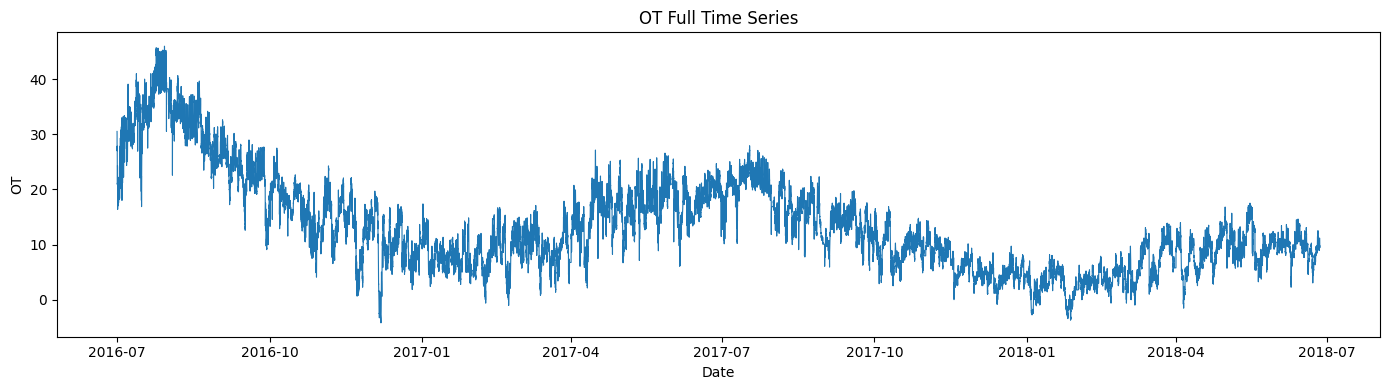

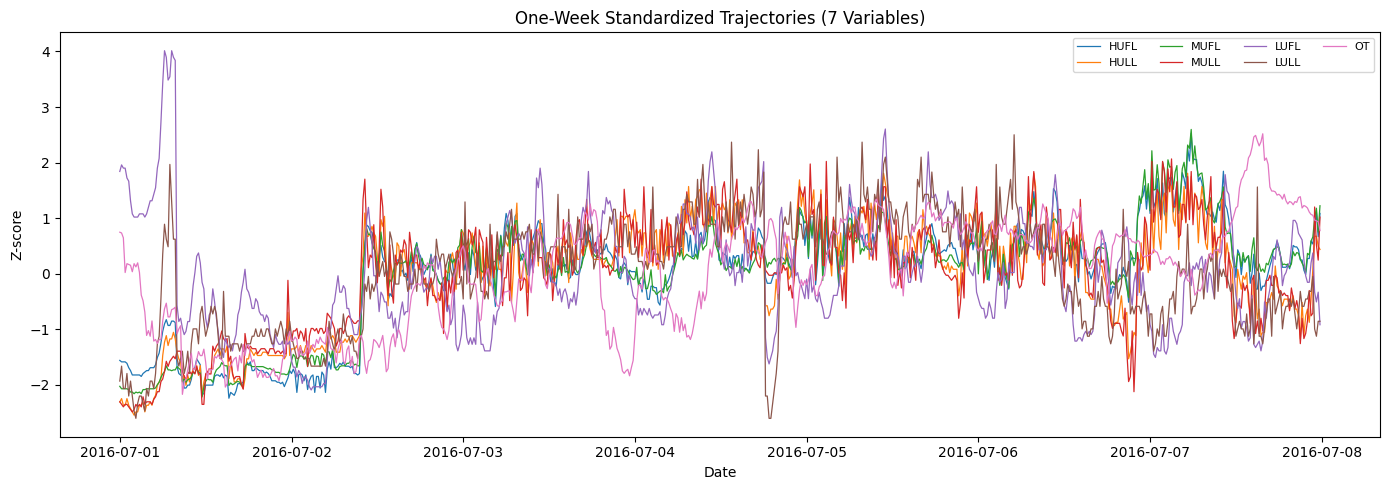

In [4]:
# EDA for multivariate M setting
base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

# Visualise long-term temporal trends and seasonal variations for the target (OT)
plt.figure(figsize=(14, 4))
plt.plot(df['date'], df['OT'], linewidth=0.8)
plt.title('OT Full Time Series')
plt.xlabel('Date')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_full_series.png'), dpi=150)
plt.show()

# Isolate a high-resolution one-week window for granular periodicity analysis
week_points = 7 * 24 * 4
subset = df.iloc[:week_points].copy()

# Standardise via Z-score to compare cross-variable trajectories and synchronization
z = subset[base_cols].copy()
z = (z - z.mean()) / (z.std() + 1e-8)
plt.figure(figsize=(14, 5))
for c in base_cols:
    plt.plot(subset['date'], z[c], linewidth=0.9, label=c)
plt.title('One-Week Standardized Trajectories (7 Variables)')
plt.xlabel('Date')
plt.ylabel('Z-score')
plt.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_week_multivariate_standardized.png'), dpi=150)
plt.show()

Key Finding: The OT series shows clear long-horizon regime shifts with recurring seasonal-like oscillations, while one-week standardized trajectories reveal synchronized short-term co-movement across variables alongside distinct feature-specific volatility and amplitude profiles.

ADF stationarity test across all target variables
Variable  ADF Statistic  p-value     Status
    HUFL       -26.7254 0.000000 Stationary
    HULL       -11.8500 0.000000 Stationary
    MUFL       -27.3297 0.000000 Stationary
    MULL       -11.4334 0.000000 Stationary
    LUFL       -16.3133 0.000000 Stationary
    LULL        -7.0483 0.000000 Stationary
      OT        -4.1916 0.000681 Stationary


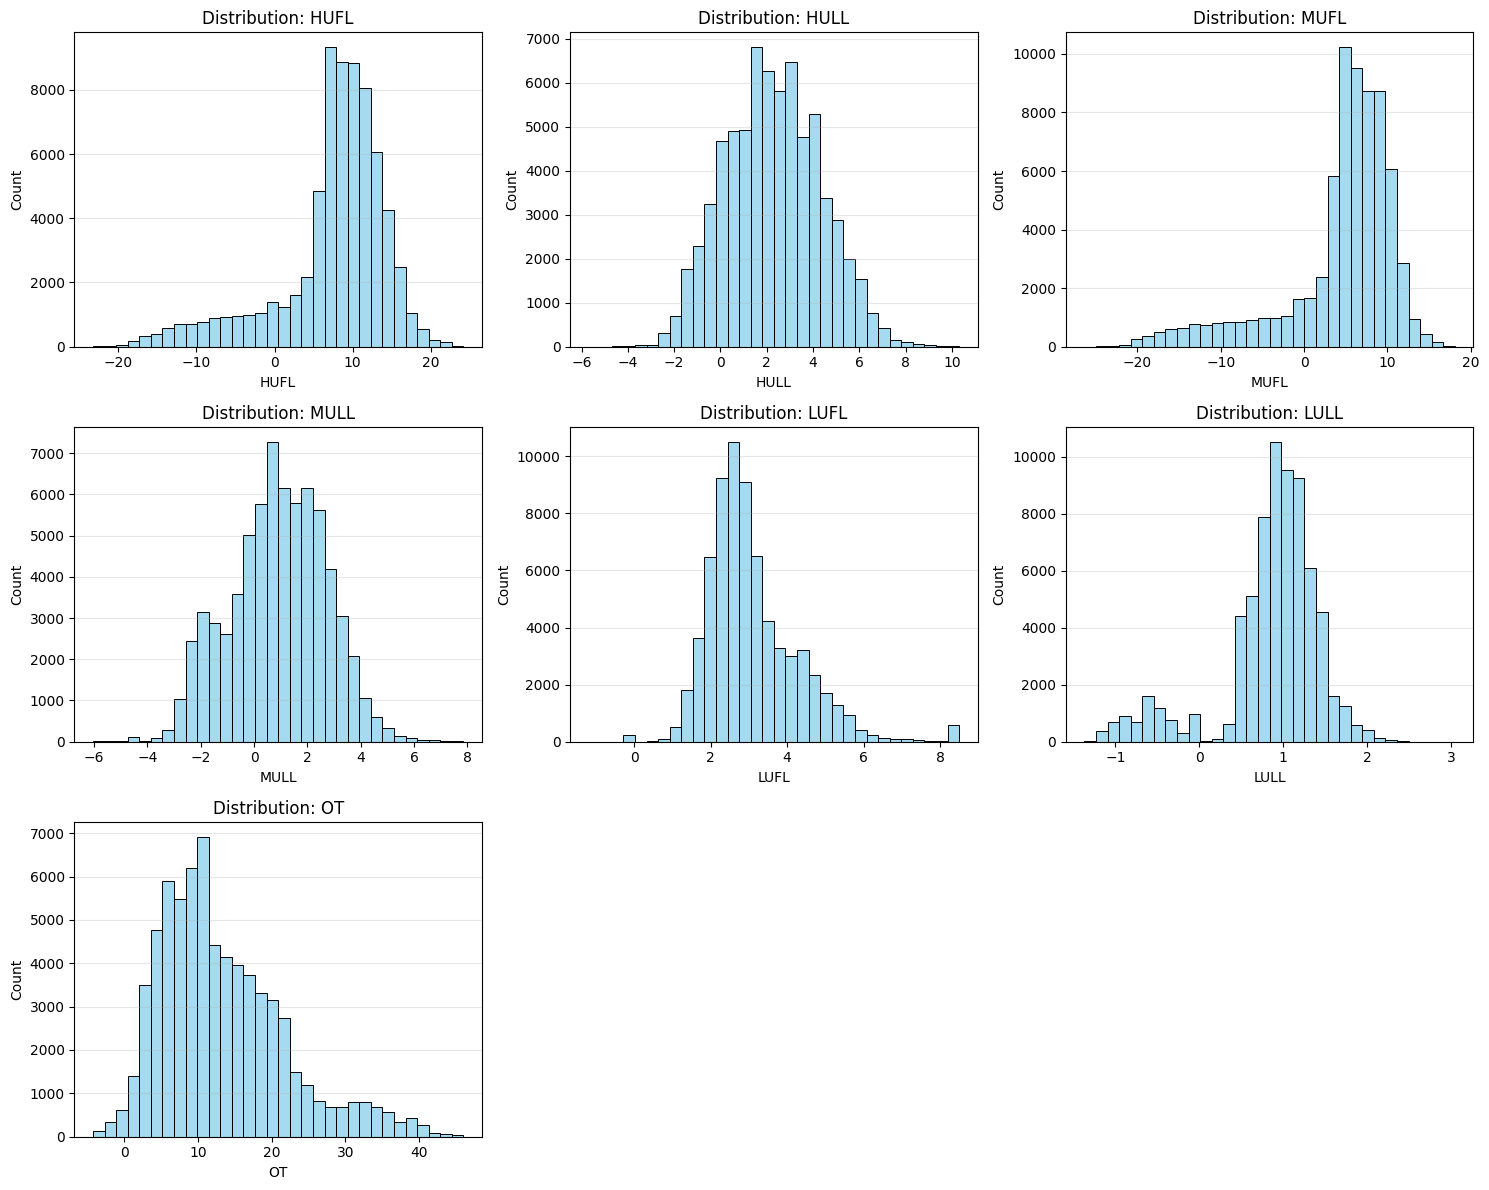

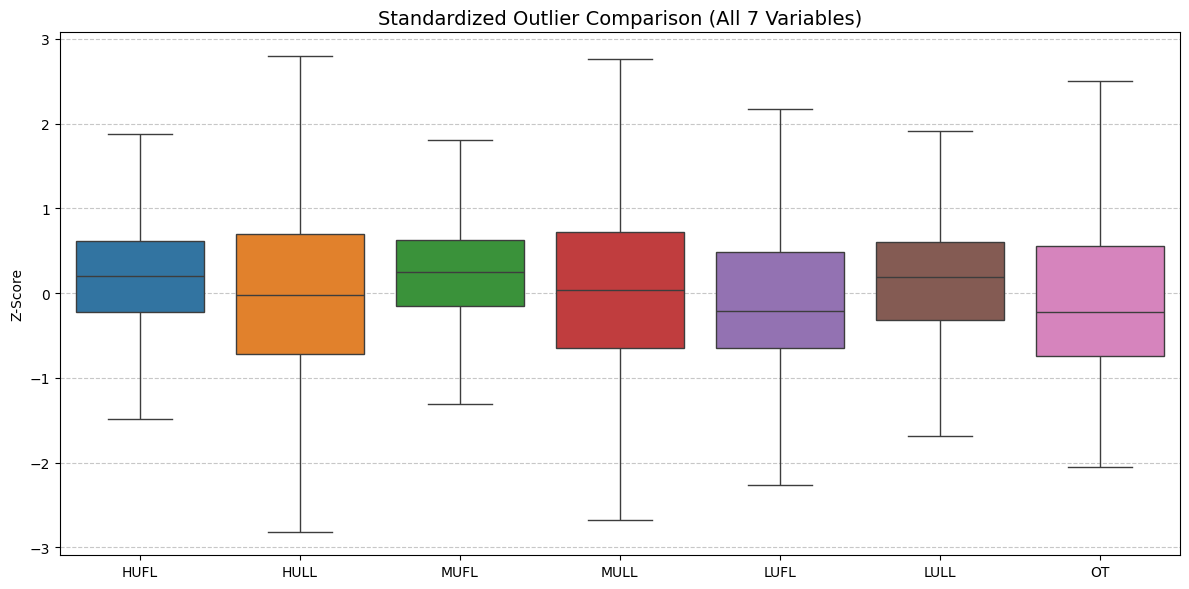

STL variables: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT'], window: 2688 points


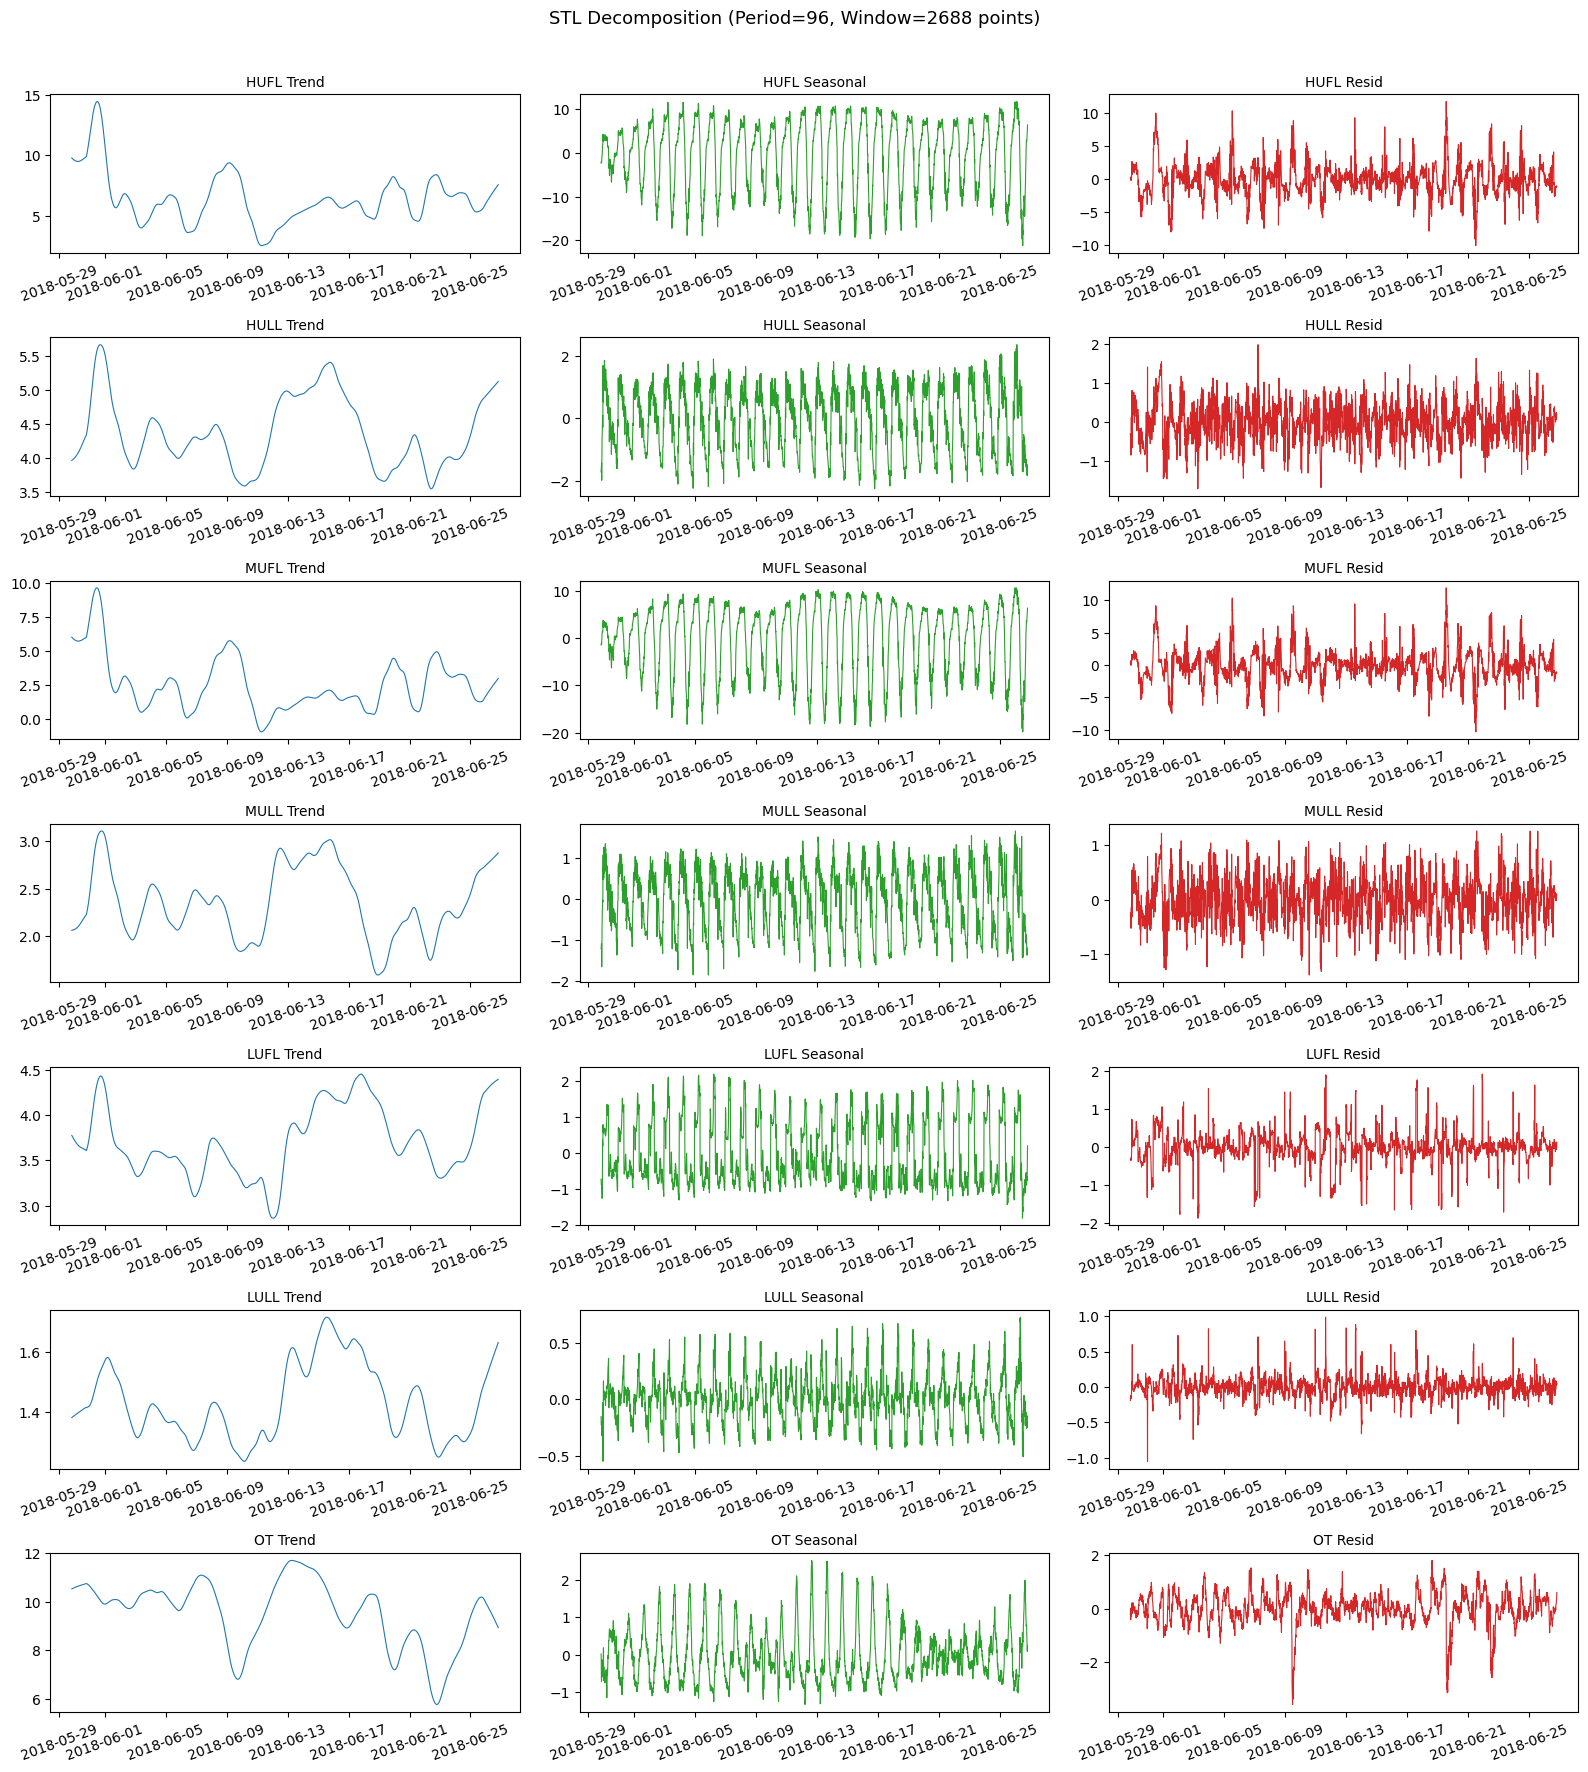

Seasonal strength summary (higher means stronger seasonality):
Variable  Seasonal Strength
    HUFL           0.913425
    MUFL           0.904844
    HULL           0.825719
    LUFL           0.809708
    MULL           0.776075
    LULL           0.694603
      OT           0.586192


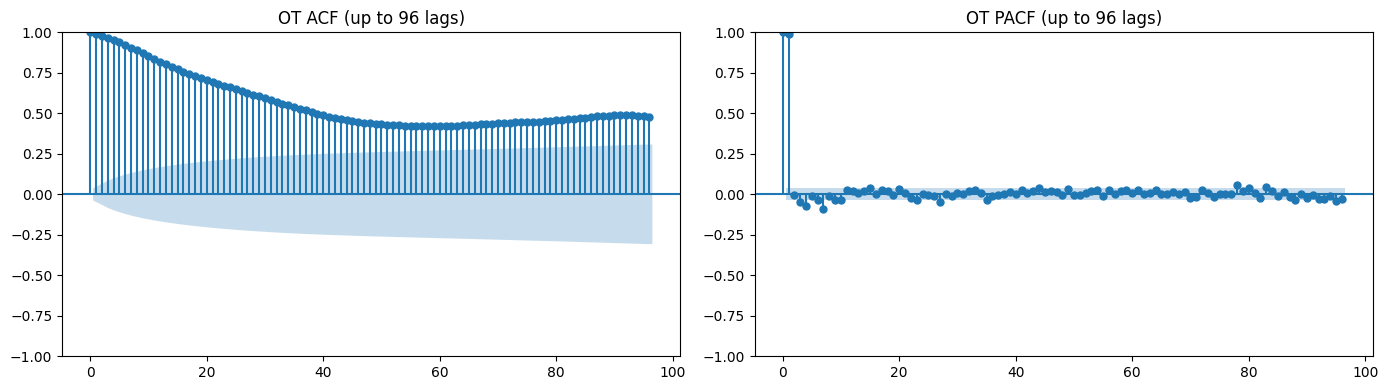

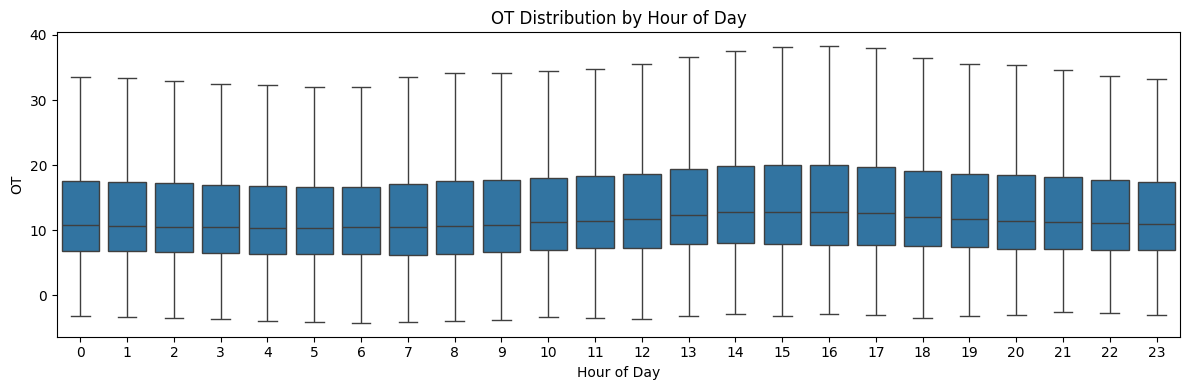

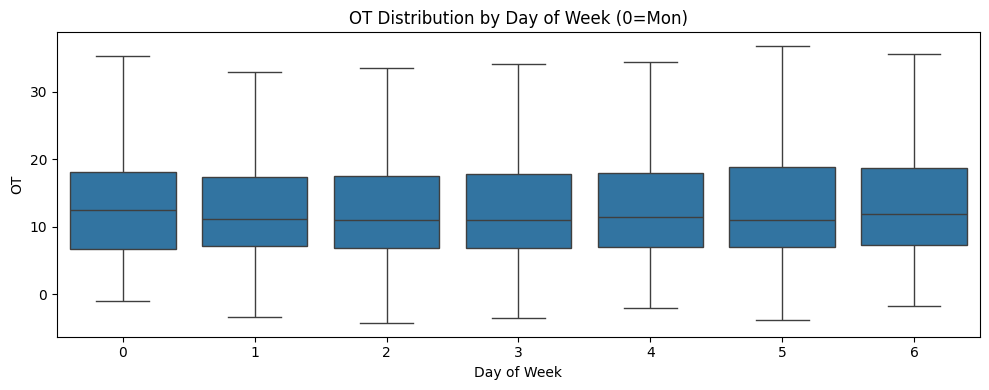

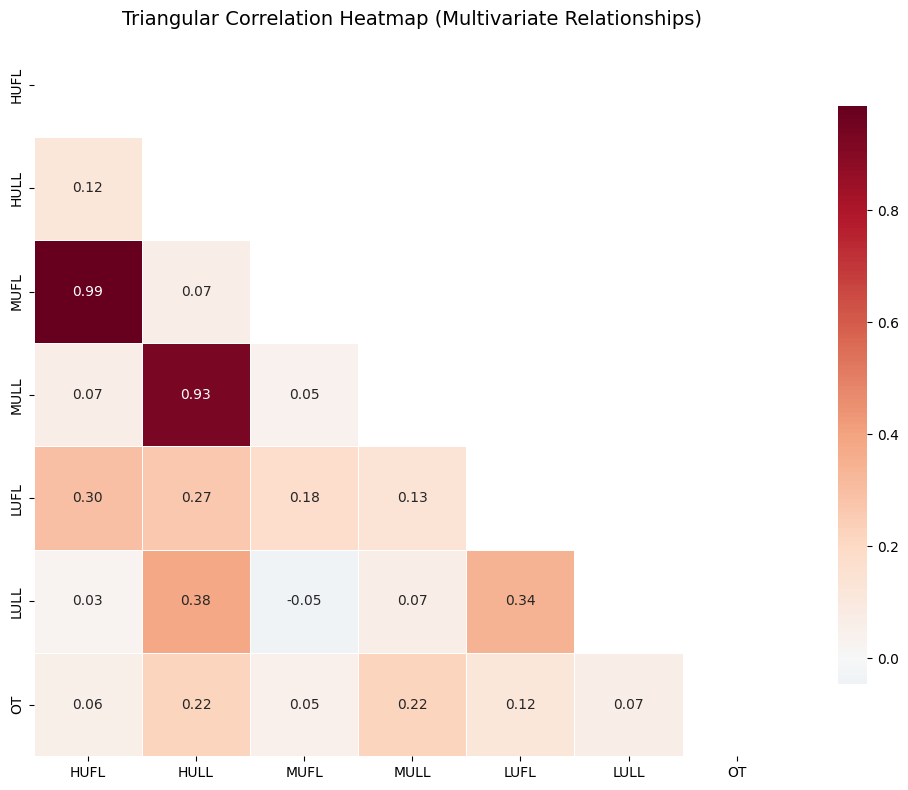

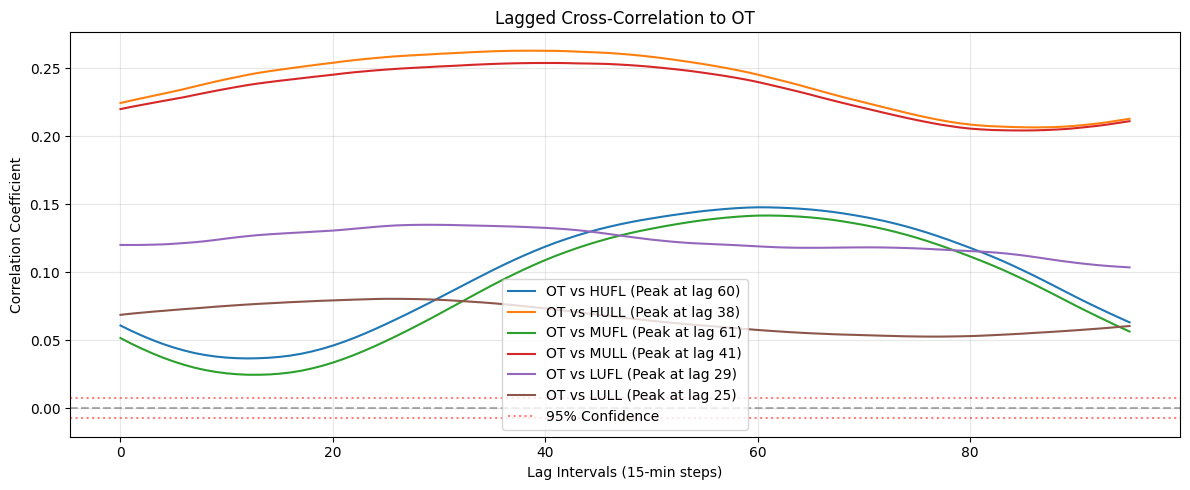

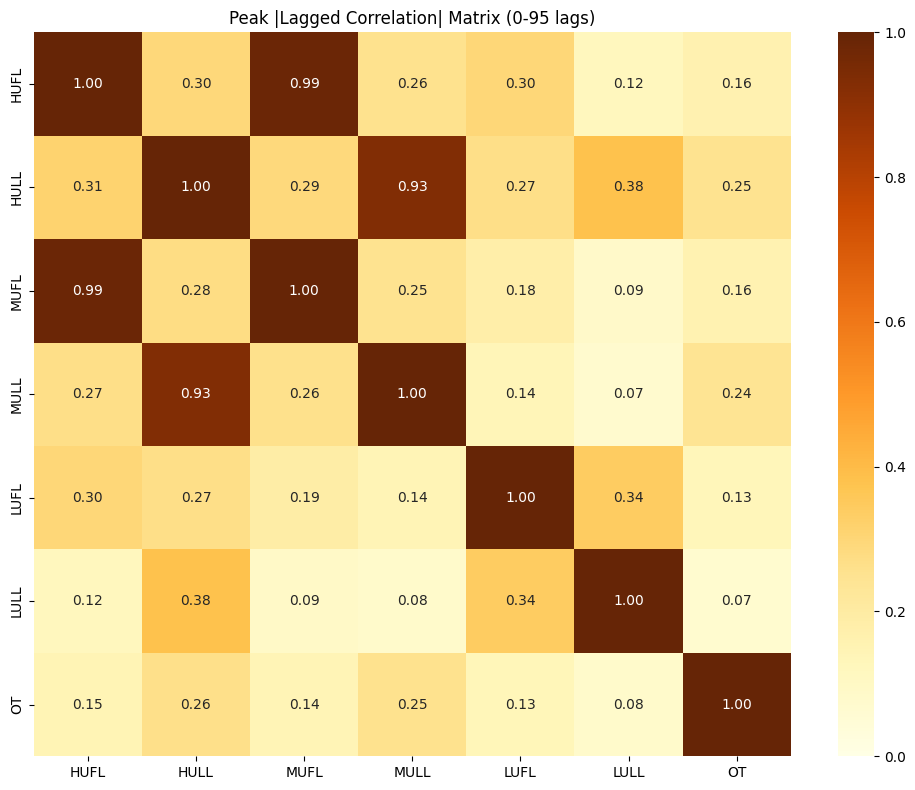

Strongest pair by peak lagged correlation: HUFL vs MUFL (0.987)
HUFL-HULL peak lagged correlation: 0.296. This may indicate feature redundancy.
EDA diagnostics completed in 94.60s


In [5]:
# Perform Augmented Dickey-Fuller (ADF) tests to verify feature stationarity and unit root presence
print('ADF stationarity test across all target variables')

if 'base_cols' not in globals():
    base_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
if 'numeric_cols' not in globals():
    numeric_cols = [c for c in base_cols if c in df.columns]
if 'date' not in df.columns:
    raise ValueError('Expected date column in dataframe.')

missing_required = [c for c in base_cols if c not in df.columns]
if len(missing_required) > 0:
    raise ValueError(f'Missing expected base columns: {missing_required}')

numeric_cols = [c for c in numeric_cols if pd.api.types.is_numeric_dtype(df[c])]
if len(numeric_cols) == 0:
    raise ValueError('No numeric columns available for EDA.')

# Maintain consistent feature ordering for all subsequent diagnostic visualisations
ordered_cols = [c for c in base_cols if c in numeric_cols]
extra_cols = [c for c in numeric_cols if c not in ordered_cols]
numeric_cols = ordered_cols + extra_cols

t0 = time.perf_counter()

adf_results = []
for col in base_cols:
    res = adfuller(df[col].values)
    is_stationary = res[1] < 0.05
    adf_results.append({
        'Variable': col,
        'ADF Statistic': float(f'{res[0]:.4f}'),
        'p-value': float(f'{res[1]:.6f}'),
        'Status': 'Stationary' if is_stationary else 'Non-Stationary'
    })

adf_df = pd.DataFrame(adf_results)
print(adf_df.to_string(index=False))

# Visualize marginal distributions to assess skewness and multi-modality
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes_flat = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, bins=32, kde=False, ax=axes_flat[i], color='skyblue')
    axes_flat[i].set_title(f'Distribution: {col}', fontsize=12)
    axes_flat[i].grid(axis='y', alpha=0.3)
for j in range(len(numeric_cols), len(axes_flat)):
    axes_flat[j].axis('off')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_distributions.png'), dpi=150)
plt.show()

# Compare feature variances and outlier profiles via standardized boxplots
plt.figure(figsize=(12, 6))
df_std = (df[numeric_cols] - df[numeric_cols].mean()) / (df[numeric_cols].std() + 1e-8)
sns.boxplot(data=df_std, showfliers=False)
plt.title('Standardized Outlier Comparison (All 7 Variables)', fontsize=14)
plt.ylabel('Z-Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_boxplot_standardized.png'), dpi=150)
plt.show()

# Execute STL decomposition to quantify trend, seasonality, and residual (noise) components
stl_period = 24 * 4
stl_cols = [c for c in base_cols if c in df.columns]
stl_points = min(len(df), stl_period * 7 * 4)  # last 4 weeks
stl_df = df[['date'] + stl_cols].iloc[-stl_points:].copy()
print(f'STL variables: {stl_cols}, window: {stl_points} points')

n_rows = len(stl_cols)
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 2.5 * n_rows), sharex=False)
if n_rows == 1:
    axes = np.array([axes])

seasonal_strength_rows = []
for i, col in enumerate(stl_cols):
    y = stl_df[col].astype(float).values
    if np.isnan(y).any():
        y = pd.Series(y).ffill().bfill().values
    stl_res = STL(y, period=stl_period, robust=False).fit()

    # Calculate seasonal strength metric: 1 - Var(resid) / Var(seasonal + resid)
    seasonal_var = np.var(stl_res.seasonal)
    resid_var = np.var(stl_res.resid)
    denom_var = seasonal_var + resid_var + 1e-8
    seasonal_strength = max(0.0, 1.0 - (resid_var / denom_var))
    seasonal_strength_rows.append({'Variable': col, 'Seasonal Strength': seasonal_strength})

    axes[i, 0].plot(stl_df['date'], stl_res.trend, linewidth=0.8, color='#1f77b4')
    axes[i, 0].set_title(f'{col} Trend', fontsize=10)
    axes[i, 1].plot(stl_df['date'], stl_res.seasonal, linewidth=0.8, color='#2ca02c')
    axes[i, 1].set_title(f'{col} Seasonal', fontsize=10)
    axes[i, 2].plot(stl_df['date'], stl_res.resid, linewidth=0.8, color='#d62728')
    axes[i, 2].set_title(f'{col} Resid', fontsize=10)
for ax in axes.flatten():
    ax.tick_params(axis='x', labelrotation=20)
plt.suptitle(f'STL Decomposition (Period=96, Window={stl_points} points)', y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_stl_decomposition_all_variables.png'), dpi=150)
plt.show()

seasonal_strength_df = pd.DataFrame(seasonal_strength_rows).sort_values('Seasonal Strength', ascending=False)
print('Seasonal strength summary (higher means stronger seasonality):')
print(seasonal_strength_df.to_string(index=False))

# Analyze ACF/PACF to identify autoregressive structures and justify the 96-step look-back window
acf_lags = min(96, max(8, len(df) // 2 - 1))
ot_points = min(len(df), stl_period * 7 * 4)
ot_series = df['OT'].iloc[-ot_points:].astype(float).values

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(ot_series, lags=acf_lags, ax=axes[0], alpha=0.05, title='OT ACF (up to 96 lags)')
plot_pacf(ot_series, lags=acf_lags, ax=axes[1], alpha=0.05, method='ywm', title='OT PACF (up to 96 lags)')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_acf_pacf_ot.png'), dpi=150)
plt.show()

# Examine intraday and weekly periodicities to confirm seasonal cyclic patterns for OT
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['date'].dt.hour, y=df['OT'], showfliers=False)
plt.title('OT Distribution by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_hour_of_day.png'), dpi=150)
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['date'].dt.dayofweek, y=df['OT'], showfliers=False)
plt.title('OT Distribution by Day of Week (0=Mon)')
plt.xlabel('Day of Week')
plt.ylabel('OT')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_day_of_week.png'), dpi=150)
plt.show()

# Compute contemporaneous Pearson correlations to identify feature redundancy and multi-collinearity
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, cmap='RdBu_r', center=0,
            fmt='.2f', linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Triangular Correlation Heatmap (Multivariate Relationships)', fontsize=14)
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_correlation_heatmap.png'), dpi=150)
plt.show()

# Compute lagged cross-correlations to identify leading indicators for the target (OT)
arr = df[numeric_cols].astype(np.float32).values
arr_z = (arr - arr.mean(axis=0, keepdims=True)) / (arr.std(axis=0, keepdims=True) + 1e-8)
lags = min(96, len(arr_z) - 2)
if lags < 2:
    raise ValueError('Not enough samples for lagged correlation diagnostics.')

p = arr_z.shape[1]
lag_peak = np.full((p, p), -np.inf, dtype=np.float32)
other_idx = []
ot_curve_mat = None
if 'OT' in numeric_cols:
    ot_idx = numeric_cols.index('OT')
    other_idx = [i for i, c in enumerate(numeric_cols) if c != 'OT']
    ot_curve_mat = np.zeros((lags, len(other_idx)), dtype=np.float32)

for k in range(lags):
    x = arr_z[k:, :]
    y = arr_z[:len(arr_z) - k, :]
    corr_k = (x.T @ y) / max(1, x.shape[0])
    lag_peak = np.maximum(lag_peak, np.abs(corr_k))
    if ot_curve_mat is not None:
        ot_curve_mat[k, :] = corr_k[ot_idx, other_idx]

if ot_curve_mat is not None:
    plt.figure(figsize=(12, 5))
    for j, idx in enumerate(other_idx):
        curve = ot_curve_mat[:, j]
        max_lag = int(np.argmax(np.abs(curve)))
        col = numeric_cols[idx]
        plt.plot(range(lags), curve, label=f'OT vs {col} (Peak at lag {max_lag})')
    conf_level = 2.0 / np.sqrt(len(df))
    plt.axhline(conf_level, color='red', linestyle=':', alpha=0.5, label='95% Confidence')
    plt.axhline(-conf_level, color='red', linestyle=':', alpha=0.5)
    plt.axhline(0, color='black', linestyle='--', alpha=0.3)
    plt.title('Lagged Cross-Correlation to OT')
    plt.xlabel('Lag Intervals (15-min steps)')
    plt.ylabel('Correlation Coefficient')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path('figures', 'Eda_lagged_cross_correlation_to_ot.png'), dpi=150)
    plt.show()

# Generate peak absolute lagged correlation matrix to summarize the global dependency structure
lag_peak_df = pd.DataFrame(lag_peak, index=numeric_cols, columns=numeric_cols)
plt.figure(figsize=(10, 8))
sns.heatmap(lag_peak_df, annot=True, cmap='YlOrBr', vmin=0, vmax=1, fmt='.2f')
plt.title('Peak |Lagged Correlation| Matrix (0-95 lags)')
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_peak_lagged_correlation_matrix.png'), dpi=150)
plt.show()

pair_series = lag_peak_df.where(~np.eye(len(lag_peak_df), dtype=bool)).stack().sort_values(ascending=False)
if len(pair_series) > 0:
    top_pair = pair_series.index[0]
    top_val = pair_series.iloc[0]
    print(f'Strongest pair by peak lagged correlation: {top_pair[0]} vs {top_pair[1]} ({top_val:.3f})')

if 'HUFL' in lag_peak_df.index and 'HULL' in lag_peak_df.columns:
    hufl_hull = float(lag_peak_df.loc['HUFL', 'HULL'])
    print(f'HUFL-HULL peak lagged correlation: {hufl_hull:.3f}. This may indicate feature redundancy.')

print(f'EDA diagnostics completed in {time.perf_counter() - t0:.2f}s')

Key Finding: All seven variables are ADF-stationary, the series exhibits strong multi-scale seasonality with the highest seasonal strength in HUFL and MUFL and a comparatively weaker but still present seasonal component in OT, OT also shows persistent autocorrelation with distinct intraday structure (higher midday levels) and mild weekday variation, and the dependency structure is dominated by very strong coupled pairs (HUFL-MUFL and HULL-MULL) while OT maintains moderate lagged associations mainly with HULL and MULL.

Front vs Back drift summary:


,HUFL_front,HULL_front,MUFL_front,MULL_front,LUFL_front,LULL_front,OT_front,HUFL_back,HULL_back,MUFL_back,MULL_back,LUFL_back,LULL_back,OT_back
mean,7.971978,2.041194,5.086975,0.768985,2.809531,0.782098,17.152580,6.856009,2.481643,3.557478,1.024033,3.356246,0.933717,9.488703
std,5.841680,2.084099,5.533875,1.924083,1.039453,0.638211,9.142191,8.098718,1.973172,7.841141,1.672633,1.235707,0.549781,5.810876


Potential Data Drift Detected
Mean shift ratio (>10%):
OT      0.446806
MULL    0.331668
MUFL    0.300669
HULL    0.215780
LUFL    0.194593
LULL    0.193862
HUFL    0.139986


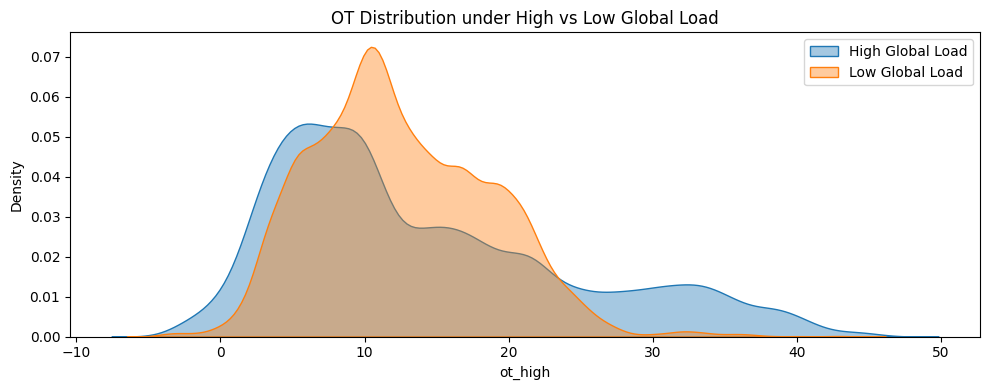

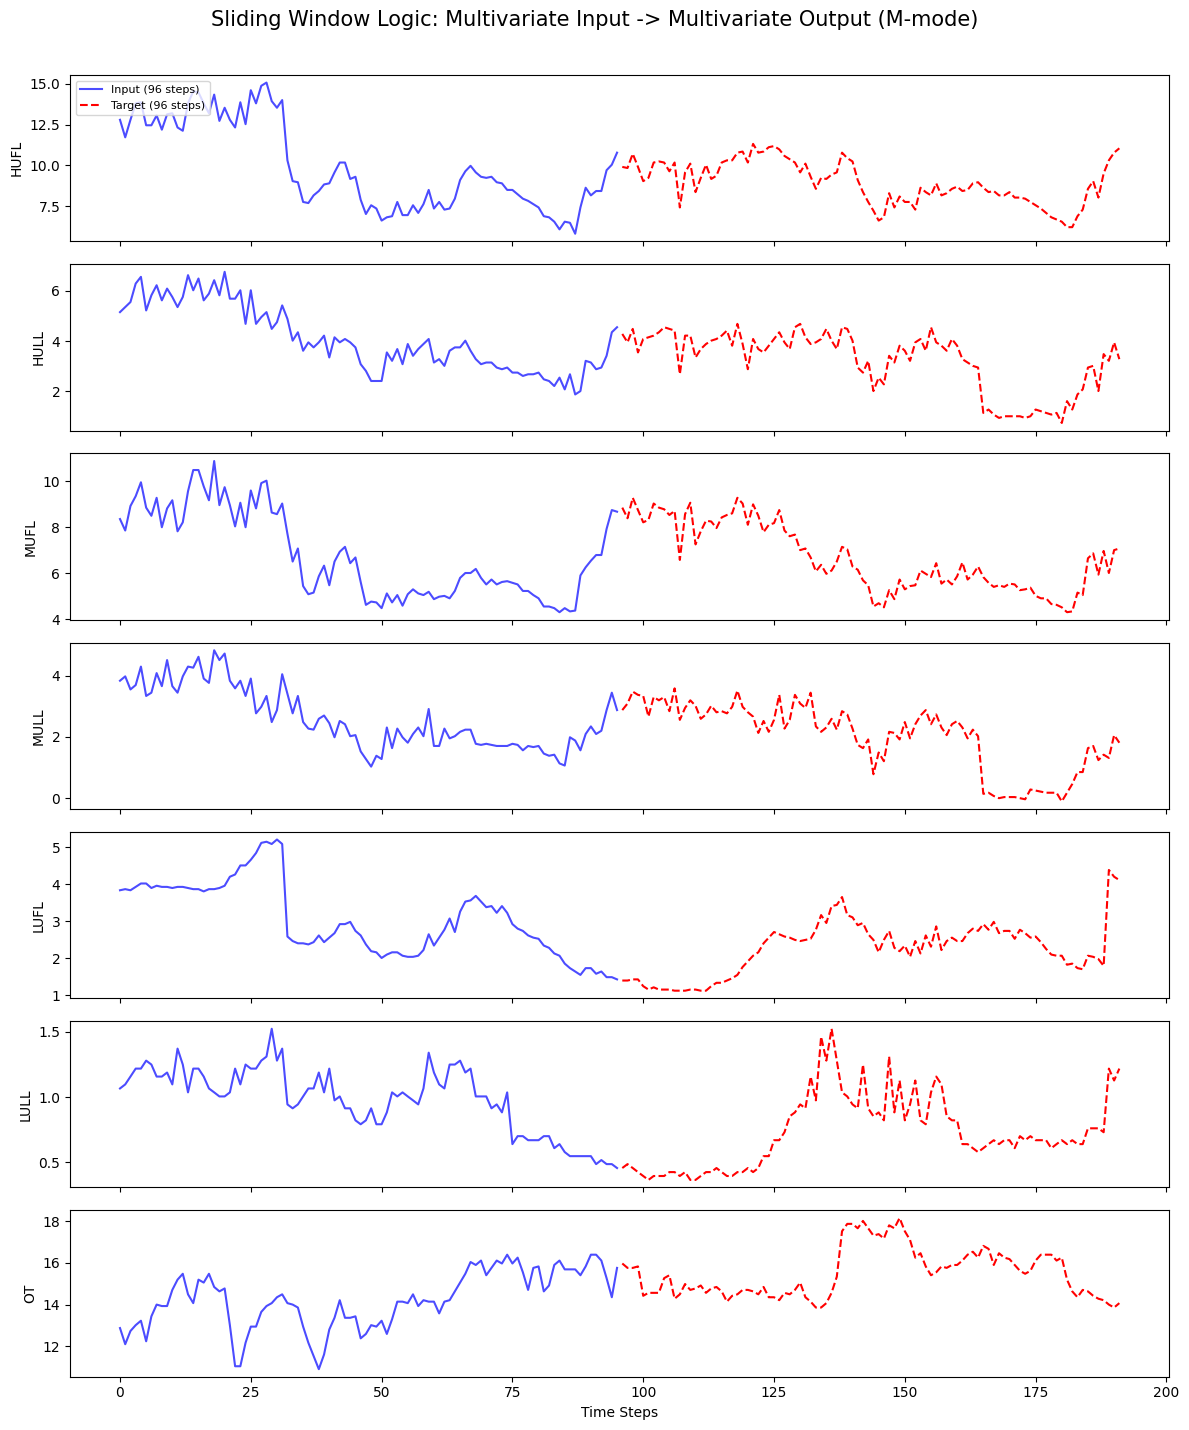

In [6]:
# Assess non-stationarity via statistical drift between temporal partitions
mid = len(df) // 2
front = df.iloc[:mid][numeric_cols].describe().loc[['mean', 'std']]
back = df.iloc[mid:][numeric_cols].describe().loc[['mean', 'std']]
drift_stats = pd.concat([front.add_suffix('_front'), back.add_suffix('_back')], axis=1)
print('Front vs Back drift summary:')
display(drift_stats)

# Detect significant covariate shift using a 10% mean-shift tolerance
mean_front = front.loc['mean']
mean_back = back.loc['mean']
mean_base = np.maximum(np.abs(mean_front.values), 1e-8)
mean_shift_ratio = np.abs(mean_back.values - mean_front.values) / mean_base
mean_shift_series = pd.Series(mean_shift_ratio, index=mean_front.index)
if (mean_shift_series > 0.10).any():
    flagged = mean_shift_series[mean_shift_series > 0.10].sort_values(ascending=False)
    print('Potential Data Drift Detected')
    print('Mean shift ratio (>10%):')
    print(flagged.to_string())
else:
    print('No significant mean drift detected (>10% threshold).')

# Evaluate target (OT) conditional distribution relative to system load intensity
load_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL']
global_load = df[load_cols].mean(axis=1)
high_load_flag = global_load > global_load.median()
high_df = df.loc[high_load_flag, ['OT']].rename(columns={'OT': 'ot_high'})
low_df = df.loc[~high_load_flag, ['OT']].rename(columns={'OT': 'ot_low'})

plt.figure(figsize=(10, 4))
sns.kdeplot(data=high_df, x='ot_high', label='High Global Load', fill=True, alpha=0.4)
sns.kdeplot(data=low_df, x='ot_low', label='Low Global Load', fill=True, alpha=0.4)
plt.title('OT Distribution under High vs Low Global Load')
plt.legend()
plt.tight_layout()
plt.savefig(out_path('figures', 'Eda_ot_by_global_load_level.png'), dpi=150)
plt.show()

# Validate sliding window logic and multivariate synchronization (M-mode)
def visualize_input_output_window(df, config):
    seq_len = config['seq_len']
    pred_len = config['pred_len']
    
    start_idx = random.randint(0, len(df) - seq_len - pred_len)
    window_data = df.iloc[start_idx : start_idx + seq_len + pred_len]
    
    fig, axes = plt.subplots(7, 1, figsize=(12, 15), sharex=True)
    cols = base_cols
    
    x_input = range(0, seq_len)
    x_output = range(seq_len, seq_len + pred_len)
    
    for i, col in enumerate(cols):
        axes[i].plot(x_input, window_data[col].iloc[:seq_len], 
                     color='blue', label='Input (96 steps)', alpha=0.7)
        axes[i].plot(x_output, window_data[col].iloc[seq_len:], 
                     color='red', label='Target (96 steps)', linestyle='--')
        axes[i].set_ylabel(col)
        if i == 0:
            axes[i].legend(loc='upper left', fontsize=8)
            
    plt.xlabel('Time Steps')
    plt.suptitle(f'Sliding Window Logic: Multivariate Input -> Multivariate Output (M-mode)', fontsize=15)
    plt.tight_layout(rect=[0, 0.03, 1, 0.97])
    plt.savefig(out_path('figures', 'Eda_input_output_window.png'), dpi=150)
    plt.show()

visualize_input_output_window(df, CONFIG)

Key Finding: The dataset shows clear front-to-back drift, dominated by OT (44.7% mean shift), with higher global load linked to a heavier OT upper tail and greater spread, and the 96-to-96 sliding-window plot confirms a coherent multivariate input-output mapping.